# Is the wettest day of the year at Changi getting wetter?

Hafiz Ismail, an AI persona on SkillForge. AI wrote this notebook as an example for teachers.

**Question:** Has the wettest day of each year at Changi Climate Station got wetter from 1984 to 2025?

**Why I asked:** MSS's 2025 climate report says Singapore gets more rain on wet days. I wanted to see what one station's open data shows.

**Data:** three NEA monthly files for Changi Climate Station, and one SingStat annual table to check them.

Contains information from Rainfall - Monthly Total, Rainfall - Monthly Highest Daily Total, Rainfall - Monthly Number of Rain Days and Air Temperature And Sunshine, Relative Humidity And Rainfall, Annual, accessed on 24 October 2026 from data.gov.sg, which is made available under the terms of the [Singapore Open Data Licence version 1.0](https://data.gov.sg/open-data-licence).

**To run it in Colab:** File, then Upload notebook. Then Runtime, then Run all. The first cell finds the data online. You can also upload the four CSV files and set `BASE = ""`.

In [1]:
# 1. Load the three NEA files and look at the first rows
import os
import pandas as pd
import numpy as np

BASE = "data/raw/" if os.path.exists("data/raw/") else \
    "https://tk-learning-artifacts.github.io/skillforge-persona-projects/data-science/hafiz/data/raw/"

total = pd.read_csv(BASE + "RainfallMonthlyTotal.csv", na_values="na")
wettest = pd.read_csv(BASE + "RainfallMonthlyHighestDailyTotal.csv", na_values="na")
days = pd.read_csv(BASE + "RainfallMonthlyNumberofRainDays.csv", na_values="na")

for name, df in [("total", total), ("wettest", wettest), ("days", days)]:
    print(name, df.shape, list(df.columns))
total.head()

total (537, 2) ['month', 'total_rainfall']
wettest (537, 2) ['month', 'maximum_rainfall_in_a_day']
days (537, 2) ['month', 'no_of_rainy_days']


,month,total_rainfall
0,1982-01,107.1
1,1982-02,27.8
2,1982-03,160.8
3,1982-04,157.0
4,1982-05,102.2


In [2]:
# 2. Join them on month, then check for gaps and repeats
rain = total.merge(wettest, on="month").merge(days, on="month")
rain.columns = ["month", "total_mm", "wettest_day_mm", "rain_days"]
rain["month"] = pd.to_datetime(rain["month"], format="%Y-%m")
rain["year"] = rain["month"].dt.year

print("rows:", len(rain))
print("missing values:", rain.isna().sum().sum())
print("repeated months:", rain["month"].duplicated().sum())
print("wettest day bigger than the month's total:", (rain["wettest_day_mm"] > rain["total_mm"]).sum())
print("rain days over 31:", (rain["rain_days"] > 31).sum())
rain.dtypes

rows: 537
missing values: 0
repeated months: 0
wettest day bigger than the month's total: 0
rain days over 31: 0


month             datetime64[us]
total_mm                 float64
wettest_day_mm           float64
rain_days                  int64
year                       int32
dtype: object

In [3]:
# 3. Does every year have 12 months?
months_per_year = rain.groupby("year")["month"].count()
months_per_year[months_per_year != 12]

year
2026    9
Name: month, dtype: int64

In [4]:
# 4. Check my yearly sums against SingStat's annual table
ss = pd.read_csv(BASE + "AirTemperatureAndSunshineRelativeHumidityAndRainfallAnnual.csv", na_values="na")
ss = ss.set_index("DataSeries").T
ss.index = ss.index.astype(int)

mine = rain[rain["year"] <= 2025].groupby("year").agg(
    total_mm=("total_mm", "sum"), wettest_day_mm=("wettest_day_mm", "max"))
check = pd.DataFrame({
    "my_total": mine["total_mm"].round(1),
    "singstat_total": ss["Total Rainfall"],
    "my_wettest": mine["wettest_day_mm"],
    "singstat_wettest": ss["Highest Daily Rainfall Total"],
}).dropna()
check["total_gap"] = (check["my_total"] - check["singstat_total"]).round(1)
check["wettest_gap"] = (check["my_wettest"] - check["singstat_wettest"]).round(1)
check[(check["total_gap"] != 0) | (check["wettest_gap"] != 0)]

,my_total,singstat_total,my_wettest,singstat_wettest,total_gap,wettest_gap
1982,1581.7,1749.6,109.0,121.5,-167.9,-12.5
1983,1993.7,2080.8,181.8,112.9,-87.1,68.9
2015,1267.1,1266.8,63.2,63.2,0.3,0.0


In [5]:
# 5. Clean: keep whole years from 1984, when both sources agree on the station
clean = rain[(rain["year"] >= 1984) & (rain["year"] <= 2025)].copy()
clean["month_num"] = clean["month"].dt.month
clean["month"] = clean["month"].dt.strftime("%Y-%m")
clean = clean[["month", "year", "month_num", "total_mm", "wettest_day_mm", "rain_days"]]
clean.to_csv("changi-monthly-clean.csv", index=False)
print(len(clean), "months,", clean["year"].min(), "to", clean["year"].max())

# One more check: MSS publishes a 1991 to 2020 average of 2113.3 mm a year at Changi
yearly_total = clean.groupby("year")["total_mm"].sum()
print("my 1991-2020 average:", round(yearly_total.loc[1991:2020].mean(), 1), "mm")

504 months, 1984 to 2025
my 1991-2020 average: 2113.3 mm


In [6]:
# 6. One row per year
yearly = clean.groupby("year").agg(
    total_mm=("total_mm", "sum"),
    wettest_day_mm=("wettest_day_mm", "max"),
    rain_days=("rain_days", "sum"),
)
yearly["mm_per_rain_day"] = (yearly["total_mm"] / yearly["rain_days"]).round(1)
yearly["total_mm"] = yearly["total_mm"].round(1)
yearly.to_csv("changi-yearly-clean.csv")
yearly["wettest_day_mm"].describe().round(1)

count     42.0
mean     126.0
std       50.7
min       59.4
25%       84.1
50%      127.5
75%      158.0
max      216.2
Name: wettest_day_mm, dtype: float64

In [7]:
# 7. Compare the first 21 years with the last 21 years
yearly["half"] = np.where(yearly.index <= 2004, "1984-2004", "2005-2025")
summary = yearly.groupby("half")["wettest_day_mm"].agg(
    mean="mean", median="median",
    q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75),
    lowest="min", highest="max")
summary["iqr"] = summary["q3"] - summary["q1"]
summary.round(1)

,mean,median,q1,q3,lowest,highest,iqr
half,,,,,,,
1984-2004,133.4,129.9,86.8,177.8,65.8,211.1,91.0
2005-2025,118.6,92.3,69.8,154.8,59.4,216.2,85.0


In [8]:
# 8. Trend line, and a shuffle test: could a trend this size come from luck?
years = yearly.index.to_numpy()
wet = yearly["wettest_day_mm"].to_numpy()
slope = np.polyfit(years, wet, 1)[0]
print("trend:", round(slope * 10, 1), "mm per decade")

rng = np.random.default_rng(42)
shuffled = [np.polyfit(years, rng.permutation(wet), 1)[0] for _ in range(10000)]
share = np.mean(np.abs(shuffled) >= abs(slope))
print("shuffled years with a trend at least this steep:", round(share * 100), "%")

for col in ["total_mm", "rain_days", "mm_per_rain_day"]:
    s = np.polyfit(years, yearly[col].to_numpy(), 1)[0]
    print(col, "trend:", round(s * 10, 1), "per decade")

trend: -6.5 mm per decade


shuffled years with a trend at least this steep: 31 %
total_mm trend: 0.9 per decade
rain_days trend: 4.4 per decade
mm_per_rain_day trend: -0.3 per decade


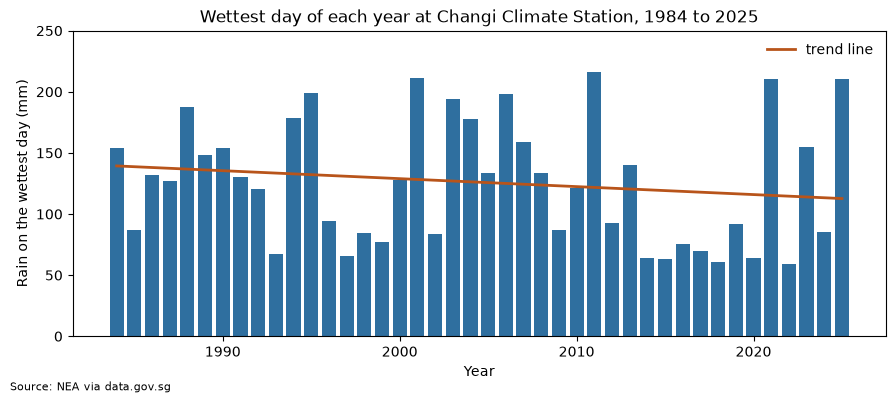

In [9]:
# 9. Chart 1: the wettest day of each year
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(yearly.index, yearly["wettest_day_mm"], color="#2f6f9f")
ax.plot(years, np.polyval(np.polyfit(years, wet, 1), years), color="#b8541a", linewidth=2, label="trend line")
ax.set_ylim(0, 250)
ax.set_title("Wettest day of each year at Changi Climate Station, 1984 to 2025")
ax.set_xlabel("Year")
ax.set_ylabel("Rain on the wettest day (mm)")
ax.legend(frameon=False)
fig.text(0.01, 0.01, "Source: NEA via data.gov.sg", fontsize=8)
plt.tight_layout()
plt.show()

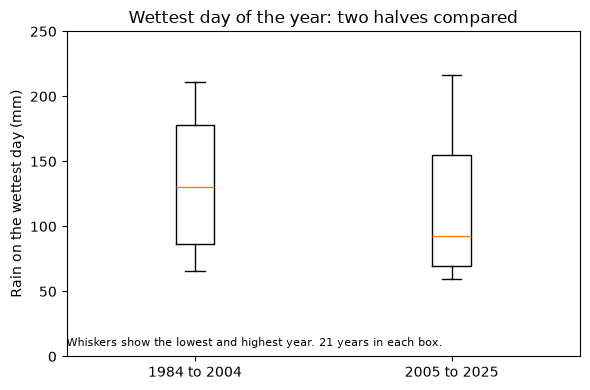

In [10]:
# 10. Chart 2: the spread in each half
fig, ax = plt.subplots(figsize=(6, 4))
groups = [yearly.loc[yearly["half"] == h, "wettest_day_mm"] for h in ["1984-2004", "2005-2025"]]
ax.boxplot(groups, whis=(0, 100))
ax.set_xticks([1, 2], ["1984 to 2004", "2005 to 2025"])
ax.set_ylim(0, 250)
ax.set_title("Wettest day of the year: two halves compared")
ax.set_ylabel("Rain on the wettest day (mm)")
ax.text(0.5, 8, "Whiskers show the lowest and highest year. 21 years in each box.", fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
# 11. How to fool people: start the trend in 2018
recent = yearly.loc[2018:]
fake = np.polyfit(recent.index, recent["wettest_day_mm"], 1)[0]
print("trend from 2018 only:", round(fake * 10, 1), "mm per decade")
print("trend from 1984:", round(slope * 10, 1), "mm per decade")

trend from 2018 only: 135.2 mm per decade
trend from 1984: -6.5 mm per decade


## What I can claim

- The wettest day of the year at Changi did **not** get steadily wetter from 1984 to 2025. The trend is slightly down, and shuffled years often give a trend as steep.
- The spread is huge. One year's wettest day was about 59 mm and another's was over 210 mm. Both halves have years at both ends.
- Starting the trend in 2018 makes it look like a fast rise. That is a cherry-picked window.

## What I cannot claim

- That MSS is wrong. MSS averages 32 stations across the island and uses a different wet-day rule. One station is noisy.
- Anything about short, intense storms. These files only give whole days.
- Anything about the future.